In [ ]:
from pathlib import Path
import csv
import gzip
import json
import platform
import subprocess
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from scipy.stats import ttest_ind, false_discovery_control
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

SEED = 42
ACCESSION = "GSE13159"
MATRIX_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE13nnn/GSE13159/matrix/GSE13159_series_matrix.txt.gz"
)

# Gerekirse proje kökünü burada değiştirin.
colab_repo = Path("/content/all-aml-gene-expression-classification")
PROJECT_ROOT = colab_repo if colab_repo.exists() else Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Önceki Colab indirmesini yeniden kullan.
DATA_DIR = (Path("/content/all_aml_external_data")
            if Path("/content").exists()
            else PROJECT_ROOT / "data" / "external" / ACCESSION)
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
for directory in [DATA_DIR, FIGURE_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MATRIX_PATH = DATA_DIR / f"{ACCESSION}_series_matrix.txt.gz"
CLASS_PALETTE = {"ALL": "steelblue", "AML": "darkorange"}
TYPE_PALETTE = {"bone marrow": "teal", "peripheral blood": "goldenrod"}
plt.rcParams["svg.fonttype"] = "none"

versions = {package: version(package) for package in
            ["numpy", "pandas", "scipy", "matplotlib", "seaborn", "scikit-learn"]}
versions["python"] = platform.python_version()
print("Proje kökü:", PROJECT_ROOT)
print("Veri klasörü:", DATA_DIR)
print(versions)


Veri seti: GSE13159
Örnek sayısı: 2096

Metadata sütunları:
['title', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'characteristics_ch1_1', 'characteristics_ch1_2', 'treatment_protocol_ch1', 'growth_protocol_ch1', 'molecule_ch1', 'extract_protocol_ch1', 'label_ch1', 'label_protocol_ch1', 'taxid_ch1', 'hyb_protocol', 'scan_protocol', 'data_processing', 'platform_id', 'contact_name', 'contact_email', 'contact_phone', 'contact_institute', 'contact_address', 'contact_city', 'contact_state', 'contact_zip/postal_code', 'contact_country', 'supplementary_file', 'data_row_count', 'relation_1', 'relation_2']


,title,source_name_ch1,characteristics_ch1_1,characteristics_ch1_2
sample_id,,,,
GSM329407,MILES stage 1 data N1_0001,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)
GSM329408,MILES stage 1 data N1_0002,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)
GSM329409,MILES stage 1 data N1_0003,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)
GSM329410,MILES stage 1 data N1_0004,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)
GSM329411,MILES stage 1 data N1_0005,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)
GSM329412,MILES stage 1 data N1_0006,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)
GSM329413,MILES stage 1 data N1_0007,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)
GSM329414,MILES stage 1 data N1_0008,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)
GSM329415,MILES stage 1 data N1_0009,Leukemia patient sample,sample type: bone marrow,leukemia class: mature B-ALL with t(8;14)



--- title: en sık görülen 25 değer ---
title
MILES stage 1 data N1_0001    1
MILES stage 1 data N1_0002    1
MILES stage 1 data N1_0003    1
MILES stage 1 data N1_0004    1
MILES stage 1 data N1_0005    1
MILES stage 1 data N1_0006    1
MILES stage 1 data N1_0007    1
MILES stage 1 data N1_0008    1
MILES stage 1 data N1_0009    1
MILES stage 1 data N1_0010    1
MILES stage 1 data N1_0011    1
MILES stage 1 data N1_0012    1
MILES stage 1 data N1_0013    1
MILES stage 1 data N1_0014    1
MILES stage 1 data N1_0015    1
MILES stage 1 data N1_0016    1
MILES stage 1 data N1_0017    1
MILES stage 1 data N1_0018    1
MILES stage 1 data N1_0019    1
MILES stage 1 data N1_0020    1
MILES stage 1 data N1_0021    1
MILES stage 1 data N1_0022    1
MILES stage 1 data N1_0023    1
MILES stage 1 data N1_0024    1
MILES stage 1 data N1_0025    1
Name: count, dtype: int64

--- source_name_ch1: en sık görülen 25 değer ---
source_name_ch1
Leukemia patient sample    2096
Name: count, dtype: int64

---

In [ ]:
def download_matrix(url, destination):
    if not destination.exists():
        staging = destination.parent / "downloads"
        staging.mkdir(exist_ok=True)
        partial = staging / destination.name
        previous_partial = destination.with_suffix(".part")
        if previous_partial.exists() and not partial.exists():
            previous_partial.replace(partial)
        print("Dosya indiriliyor / indirmeye devam ediliyor...", flush=True)
        subprocess.run([
            "wget", "--continue", "--tries=10", "--timeout=60",
            "--waitretry=5", "--retry-connrefused",
            "--retry-on-http-error=429,500,502,503,504",
            "--progress=dot:giga", "--directory-prefix", str(staging), url
        ], check=True)
        subprocess.run(["gzip", "-t", str(partial)], check=True)
        partial.replace(destination)
    else:
        subprocess.run(["gzip", "-t", str(destination)], check=True)
    print(f"Dosya hazır: {destination.stat().st_size / 1024**2:.1f} MiB")

download_matrix(MATRIX_URL, MATRIX_PATH)


Seçilen örnek sayısı: 1292
Kapsam dışında kalan örnek sayısı: 804

Sınıf dağılımı:


,sample_count
class,
ALL,750
AML,542



Sınıf × örnek türü:


sample_type,bone marrow,peripheral blood,All
class,,,
ALL,710,40,750
AML,501,41,542
All,1211,81,1292



Kapsam dışında kalan sınıflar:


,sample_count
original_class,
CLL,448
MDS,206
CML,76
Non-leukemia and healthy bone marrow,74



Seçilen örneklerin platformları:
platform_id
GPL570    1292
Name: count, dtype: int64

Veriye uygulanmış ön işlemler:
Data pre-processing included a summarization and quantile normalization step to generate probe set level signal intensities for each microarray experiment and was performed as previously published by Liu WM et al. PQN and DQN: algorithms for expression microarrays. J.Theor.Biol. 2006;243:273-278.



In [ ]:
from pathlib import Path
import gzip
import requests
import numpy as np
import pandas as pd

# İndirilen dosya Colab çalışma alanında tutulur.
DATA_DIR_EXTERNAL = Path("/content/all_aml_external_data")
DATA_DIR_EXTERNAL.mkdir(parents=True, exist_ok=True)

matrix_path = DATA_DIR_EXTERNAL / f"{ACCESSION}_series_matrix.txt.gz"

# Yarım kalan indirme, tamamlanmış dosya olarak kullanılmasın.
if not matrix_path.exists():
    temporary_path = matrix_path.with_suffix(".part")

    print("Veri dosyası indiriliyor...")
    with requests.get(MATRIX_URL, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        with temporary_path.open("wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    temporary_path.replace(matrix_path)

print(f"Dosya boyutu: {matrix_path.stat().st_size / 1024**2:.1f} MB")

# Ekspresyon tablosunun başladığı satırı bul.
skiprows = None

with gzip.open(matrix_path, "rt", encoding="utf-8") as stream:
    for line_number, line in enumerate(stream):
        if line.startswith("!series_matrix_table_begin"):
            skiprows = line_number + 1
            break

assert skiprows is not None, "Ekspresyon tablosu bulunamadı."

sample_ids = selected_metadata.index.tolist()

# Yalnızca ALL/AML örneklerini oku.
# comment='!' tablonun sonundaki GEO işaretini atlar.
expression = pd.read_csv(
    matrix_path,
    compression="gzip",
    sep="\t",
    skiprows=skiprows,
    comment="!",
    usecols=["ID_REF"] + sample_ids,
    dtype={
        "ID_REF": "string",
        **{sample_id: "float32" for sample_id in sample_ids}
    }
).set_index("ID_REF")

assert expression.index.is_unique, "Tekrarlanan prob kimliği var."

# Satırlar örnek, sütunlar prob; sıra metadata ile aynı.
X_external = expression.loc[:, sample_ids].T.copy()
X_external.index.name = "sample_id"
X_external.columns.name = "probe_id"

y_external = selected_metadata.loc[
    X_external.index, "target"
].copy()

assert X_external.index.equals(y_external.index)
assert X_external.shape[0] == 1292

del expression

print("\nEkspresyon matrisi (örnek, prob):", X_external.shape)
print("Etiketlerle örnek sırası eşleşiyor.")

values = X_external.to_numpy()

print("\nEksik değer sayısı:", int(np.isnan(values).sum()))
print("Sonsuz değer sayısı:", int(np.isinf(values).sum()))
print("Negatif değer sayısı:", int((values < 0).sum()))
print("Sıfır değer sayısı:", int((values == 0).sum()))

finite_values = values[np.isfinite(values)]
assert finite_values.size > 0, "Sonlu ekspresyon değeri bulunamadı."

quantiles = pd.Series(
    np.quantile(
        finite_values,
        [0, 0.01, 0.25, 0.50, 0.75, 0.99, 1]
    ),
    index=["Minimum", "%1", "%25", "Medyan", "%75", "%99", "Maksimum"],
    name="Expression value"
)

display(quantiles.to_frame())
display(X_external.iloc[:5, :5])

del finite_values

Dosya boyutu: 845.5 MB

Ekspresyon matrisi (örnek, prob): (1292, 54675)
Etiketlerle örnek sırası eşleşiyor.

Eksik değer sayısı: 58140
Sonsuz değer sayısı: 0
Negatif değer sayısı: 0
Sıfır değer sayısı: 225845


,Expression value
Minimum,0.000000
%1,0.007585
%25,0.123870
Medyan,0.249634
%75,0.415304
%99,0.805776
Maksimum,1.000000


probe_id,1007_s_at,1053_at,117_at,121_at,1255_g_at
sample_id,,,,,
GSM329407,0.361346,0.450274,0.431178,0.405517,0.160812
GSM329408,0.396426,0.559457,0.402577,0.437968,0.089130
GSM329409,0.419317,0.436466,0.306609,0.479352,0.117863
GSM329410,0.424651,0.512677,0.217119,0.484471,0.222672
GSM329411,0.287776,0.194097,0.355157,0.453368,0.180248


In [ ]:
# Eksiklerin problara ve örneklere nasıl dağıldığını incele.
missing_per_probe = X_external.isna().sum(axis=0)
missing_per_sample = X_external.isna().sum(axis=1)

all_missing_probes = missing_per_probe.index[
    missing_per_probe == len(X_external)
]

partial_missing_probes = missing_per_probe.index[
    (missing_per_probe > 0)
    & (missing_per_probe < len(X_external))
]

print("Tamamen eksik prob sayısı:", len(all_missing_probes))
print("Kısmen eksik prob sayısı:", len(partial_missing_probes))

print("\nÖrnek başına eksik değer sayısının dağılımı:")
display(
    missing_per_sample.value_counts()
    .sort_index()
    .rename_axis("missing_values_per_sample")
    .to_frame("sample_count")
)

print("\nTamamen eksik problar:")
print(all_missing_probes.tolist())

# Ham matrisi koru; yalnızca tümü eksik probları ayrı kopyadan çıkar.
X_external_clean = X_external.drop(
    columns=all_missing_probes
).copy()

remaining_missing = int(X_external_clean.isna().sum().sum())

print("\nYeni matris boyutu:", X_external_clean.shape)
print("Kalan eksik değer sayısı:", remaining_missing)
print(
    "Sabit prob sayısı:",
    int((X_external_clean.nunique(dropna=True) == 1).sum())
)

assert X_external_clean.index.equals(y_external.index)

Tamamen eksik prob sayısı: 45
Kısmen eksik prob sayısı: 0

Örnek başına eksik değer sayısının dağılımı:


,sample_count
missing_values_per_sample,
45,1292



Tamamen eksik problar:
['AFFX-BioB-3_at', 'AFFX-BioB-5_at', 'AFFX-BioB-M_at', 'AFFX-BioC-3_at', 'AFFX-BioC-5_at', 'AFFX-BioDn-3_at', 'AFFX-BioDn-5_at', 'AFFX-CreX-3_at', 'AFFX-CreX-5_at', 'AFFX-DapX-3_at', 'AFFX-DapX-5_at', 'AFFX-DapX-M_at', 'AFFX-LysX-3_at', 'AFFX-LysX-5_at', 'AFFX-LysX-M_at', 'AFFX-PheX-3_at', 'AFFX-PheX-5_at', 'AFFX-PheX-M_at', 'AFFX-r2-Bs-dap-3_at', 'AFFX-r2-Bs-dap-5_at', 'AFFX-r2-Bs-dap-M_at', 'AFFX-r2-Bs-lys-3_at', 'AFFX-r2-Bs-lys-5_at', 'AFFX-r2-Bs-lys-M_at', 'AFFX-r2-Bs-phe-3_at', 'AFFX-r2-Bs-phe-5_at', 'AFFX-r2-Bs-phe-M_at', 'AFFX-r2-Bs-thr-3_s_at', 'AFFX-r2-Bs-thr-5_s_at', 'AFFX-r2-Bs-thr-M_s_at', 'AFFX-r2-Ec-bioB-3_at', 'AFFX-r2-Ec-bioB-5_at', 'AFFX-r2-Ec-bioB-M_at', 'AFFX-r2-Ec-bioC-3_at', 'AFFX-r2-Ec-bioC-5_at', 'AFFX-r2-Ec-bioD-3_at', 'AFFX-r2-Ec-bioD-5_at', 'AFFX-r2-P1-cre-3_at', 'AFFX-r2-P1-cre-5_at', 'AFFX-ThrX-3_at', 'AFFX-ThrX-5_at', 'AFFX-ThrX-M_at', 'AFFX-TrpnX-3_at', 'AFFX-TrpnX-5_at', 'AFFX-TrpnX-M_at']

Yeni matris boyutu: (1292, 54630)
Kalan e

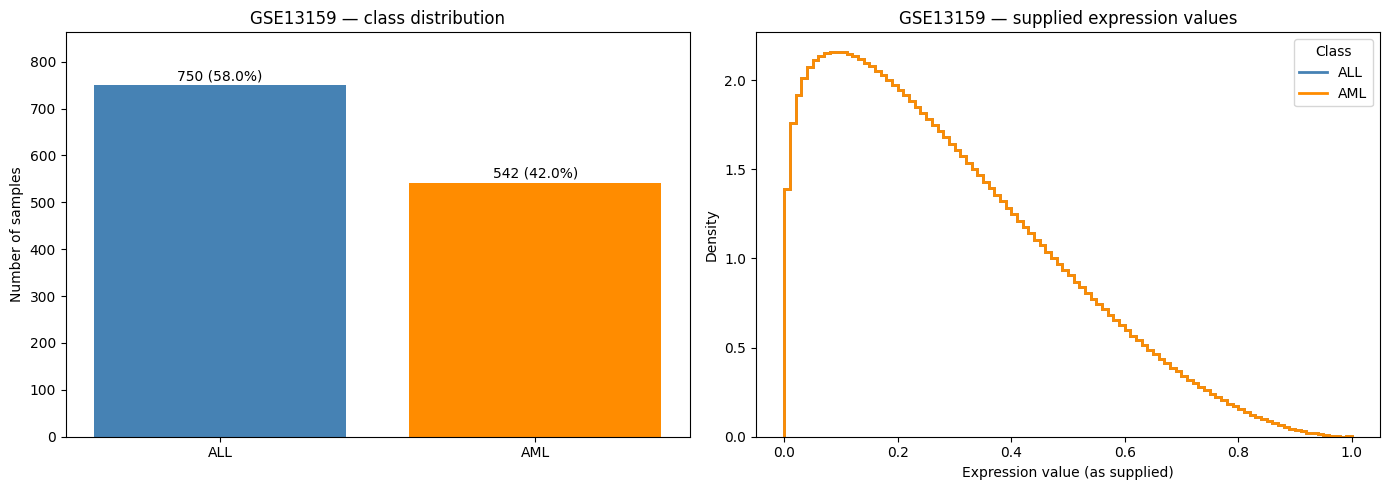

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

assert X_external_clean.index.equals(y_external.index)
assert not X_external_clean.isna().any().any()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Sınıf dağılımı
counts = y_external.value_counts().reindex([0, 1])
colors = ["steelblue", "darkorange"]

bars = axes[0].bar(["ALL", "AML"], counts.values, color=colors)

for bar, count in zip(bars, counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        count + 10,
        f"{count} ({100 * count / counts.sum():.1f}%)",
        ha="center"
    )

axes[0].set_title("GSE13159 — class distribution")
axes[0].set_ylabel("Number of samples")
axes[0].set_ylim(0, counts.max() * 1.15)

# 2. Ortak aralıklarla sınıf bazında ekspresyon histogramı
bins = np.linspace(0, 1, 101)
values = X_external_clean.to_numpy(copy=False)
labels = y_external.to_numpy()

assert np.isfinite(values).all()
assert values.min() >= 0 and values.max() <= 1

for label, name, color in [
    (0, "ALL", "steelblue"),
    (1, "AML", "darkorange")
]:
    histogram = np.zeros(len(bins) - 1, dtype=np.int64)

    for row_index in np.flatnonzero(labels == label):
        row_counts, _ = np.histogram(values[row_index], bins=bins)
        histogram += row_counts

    # Farklı sınıf büyüklüklerini karşılaştırmak için yoğunluk.
    density = histogram / (histogram.sum() * np.diff(bins))

    axes[1].stairs(
        density,
        bins,
        label=name,
        color=color,
        linewidth=2
    )

axes[1].set_title("GSE13159 — supplied expression values")
axes[1].set_xlabel("Expression value (as supplied)")
axes[1].set_ylabel("Density")
axes[1].legend(title="Class")

plt.tight_layout()
plt.show()

Sınıf ve örnek türüne göre özet:


sample_count  median_of_sample_medians  \
class sample_type                                                
ALL   bone marrow                710                  0.249634   
      peripheral blood            40                  0.249634   
AML   bone marrow                501                  0.249634   
      peripheral blood            41                  0.249634   

                        median_of_sample_IQRs  
class sample_type                              
ALL   bone marrow                    0.291428  
      peripheral blood               0.291428  
AML   bone marrow                    0.291428  
      peripheral blood               0.291428

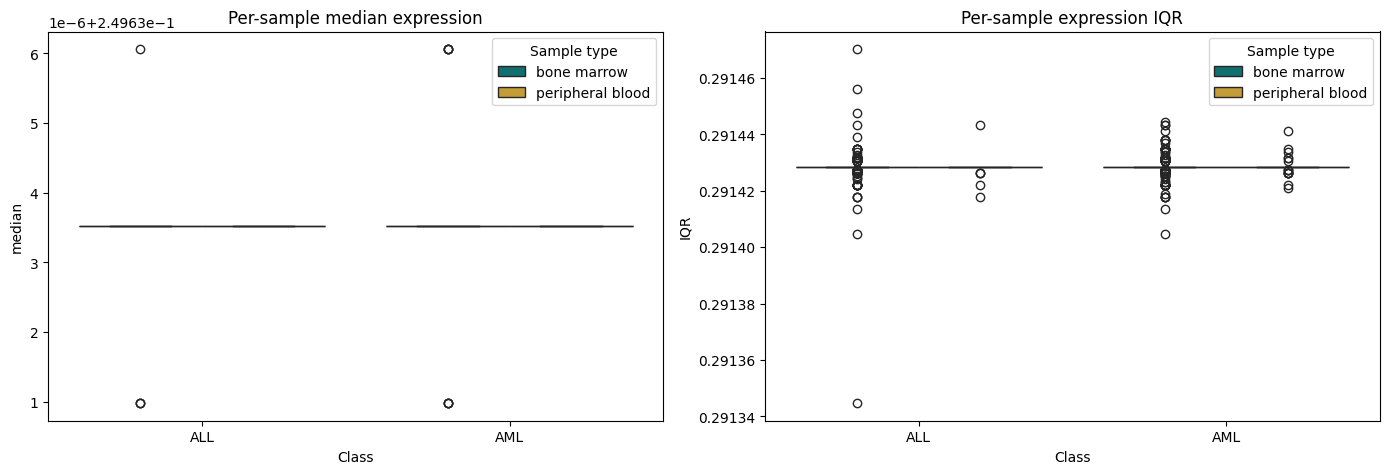


IQR değeri en yüksek 10 örnek:


,class,sample_type,median,IQR
sample_id,,,,
GSM330129,ALL,bone marrow,0.249634,0.291470
GSM329830,ALL,bone marrow,0.249634,0.291456
GSM330147,ALL,bone marrow,0.249631,0.291448
GSM330477,AML,bone marrow,0.249634,0.291444
GSM330911,AML,bone marrow,0.249634,0.291443
GSM330457,AML,bone marrow,0.249634,0.291443
GSM329417,ALL,peripheral blood,0.249634,0.291443
GSM330006,ALL,bone marrow,0.249634,0.291443
GSM330832,AML,peripheral blood,0.249634,0.291441


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Örnek bilgilerini ekspresyon matrisinin sırasına getir.
sample_summary = selected_metadata.loc[
    X_external_clean.index,
    ["class", "sample_type"]
].copy()

# Her örneğin tüm probları üzerinden özet değerler.
quartiles = X_external_clean.quantile(
    [0.25, 0.50, 0.75], axis=1
).T

sample_summary["median"] = quartiles[0.50]
sample_summary["IQR"] = quartiles[0.75] - quartiles[0.25]

print("Sınıf ve örnek türüne göre özet:")
display(
    sample_summary.groupby(["class", "sample_type"]).agg(
        sample_count=("median", "size"),
        median_of_sample_medians=("median", "median"),
        median_of_sample_IQRs=("IQR", "median")
    )
)

# Her kutu, ilgili gruptaki örnek özetlerinin dağılımıdır.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, title in [
    (axes[0], "median", "Per-sample median expression"),
    (axes[1], "IQR", "Per-sample expression IQR")
]:
    sns.boxplot(
        data=sample_summary,
        x="class",
        y=metric,
        hue="sample_type",
        order=["ALL", "AML"],
        hue_order=["bone marrow", "peripheral blood"],
        palette={
            "bone marrow": "teal",
            "peripheral blood": "goldenrod"
        },
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Class")
    ax.set_ylabel(metric)
    ax.legend(title="Sample type")

plt.tight_layout()
plt.show()

print("\nIQR değeri en yüksek 10 örnek:")
display(sample_summary.sort_values("IQR", ascending=False).head(10))

PCA'da kullanılan prob sayısı: 54630
Sabit prob sayısı: 0
PC1 açıklanan varyans: %9.97
PC2 açıklanan varyans: %6.64
İlk iki bileşen toplamı: %16.61


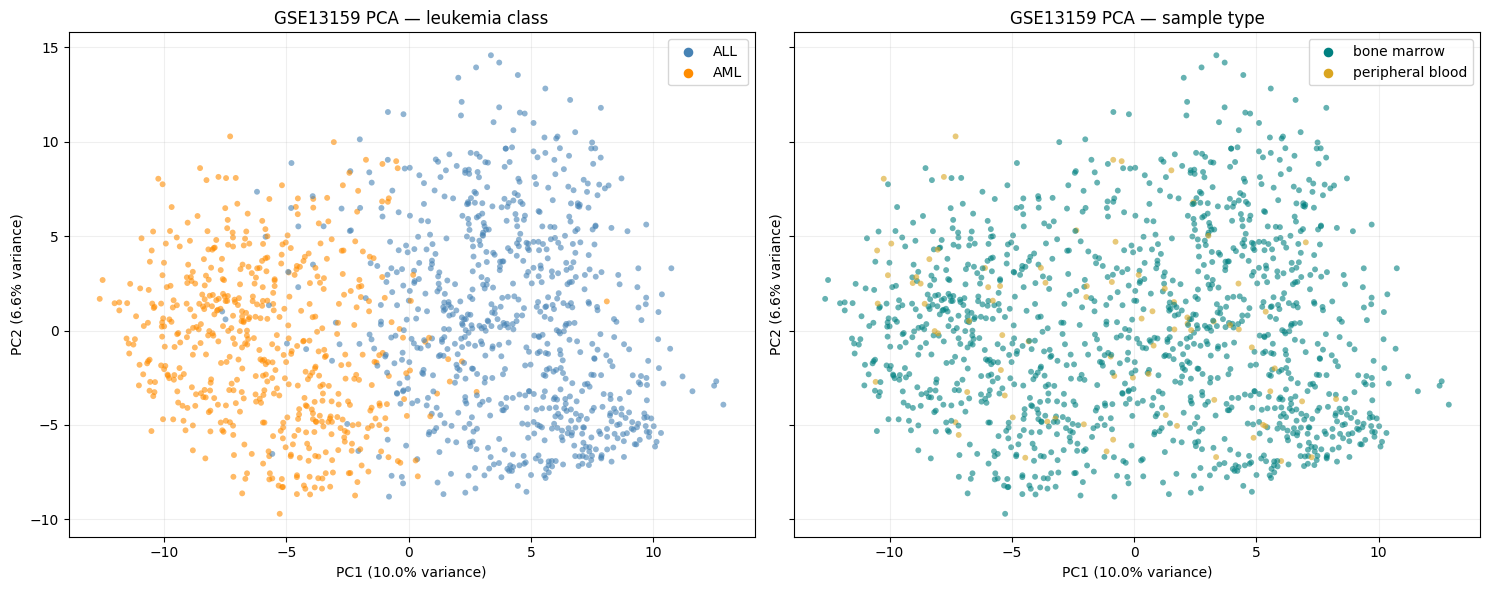

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Sabit probları yalnızca PCA girdisinden çıkar.
# X_external_clean korunur.
probe_variance = X_external_clean.var(axis=0, ddof=0)
variable_mask = probe_variance > 0

X_external_pca = X_external_clean.loc[:, variable_mask]

print("PCA'da kullanılan prob sayısı:", X_external_pca.shape[1])
print("Sabit prob sayısı:", int((~variable_mask).sum()))

# Büyük matris için randomized çözüm.
# Ek log dönüşümü veya birim varyansa ölçekleme uygulanmaz.
# PCA, prob değerlerini kendi ortalamaları etrafında merkezler.
pca_external = PCA(
    n_components=2,
    svd_solver="randomized",
    random_state=42
)

coordinates = pca_external.fit_transform(X_external_pca)
variance = pca_external.explained_variance_ratio_ * 100

print(f"PC1 açıklanan varyans: %{variance[0]:.2f}")
print(f"PC2 açıklanan varyans: %{variance[1]:.2f}")
print(f"İlk iki bileşen toplamı: %{variance.sum():.2f}")

pca_table = selected_metadata.loc[
    X_external_pca.index,
    ["class", "sample_type"]
].copy()

pca_table["PC1"] = coordinates[:, 0]
pca_table["PC2"] = coordinates[:, 1]

# Sabit çizim sırası: bir sınıfın sürekli en üstte kalmasını azaltır.
plot_table = pca_table.sample(frac=1, random_state=42)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6), sharex=True, sharey=True
)

panels = [
    (
        axes[0],
        "class",
        {"ALL": "steelblue", "AML": "darkorange"},
        "GSE13159 PCA — leukemia class"
    ),
    (
        axes[1],
        "sample_type",
        {"bone marrow": "teal", "peripheral blood": "goldenrod"},
        "GSE13159 PCA — sample type"
    )
]

for ax, column, palette, title in panels:
    ax.scatter(
        plot_table["PC1"],
        plot_table["PC2"],
        c=plot_table[column].map(palette),
        s=18,
        alpha=0.6,
        edgecolors="none"
    )

    # Açıklama için renk anahtarı.
    for name, color in palette.items():
        ax.scatter([], [], color=color, label=name, s=35)

    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({variance[0]:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({variance[1]:.1f}% variance)")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

50 PCA bileşeninin açıkladığı varyans: %50.69


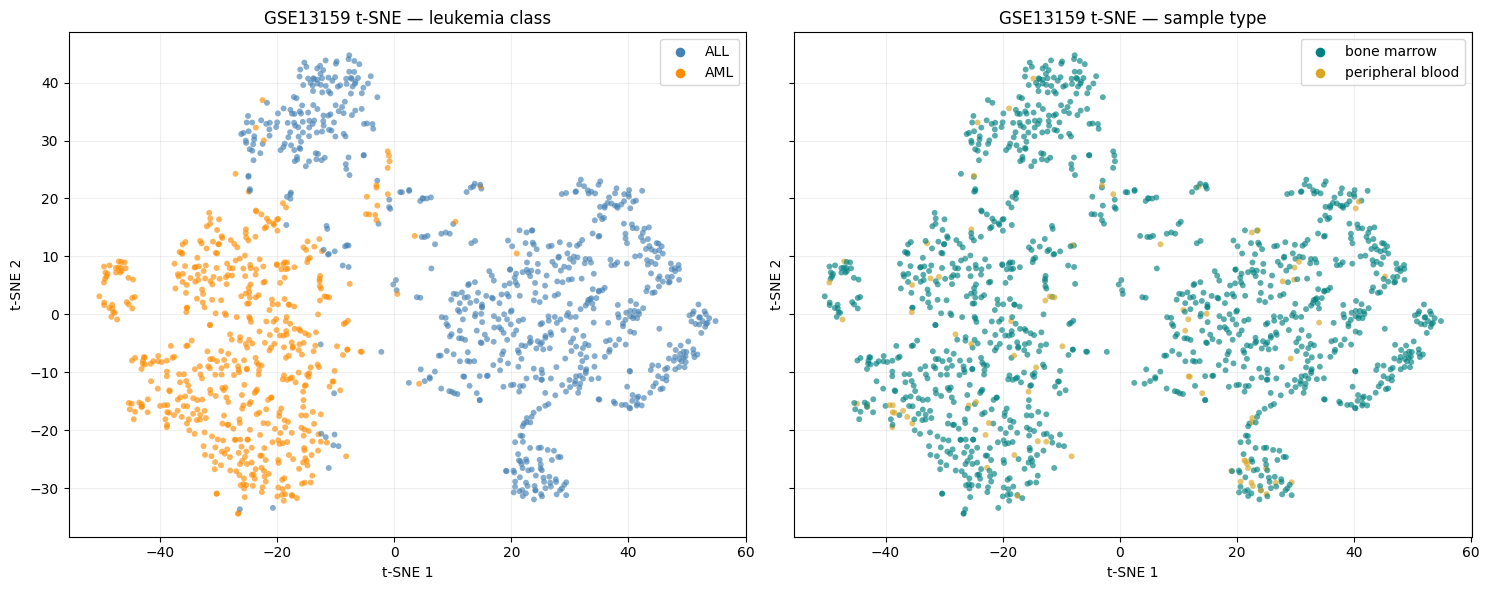

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# t-SNE öncesi boyut azaltma.
pca_for_tsne_external = PCA(
    n_components=50,
    svd_solver="randomized",
    random_state=42
)

X_external_reduced = pca_for_tsne_external.fit_transform(
    X_external_pca
)

explained = (
    pca_for_tsne_external.explained_variance_ratio_.sum() * 100
)
print(f"50 PCA bileşeninin açıkladığı varyans: %{explained:.2f}")

tsne_external = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    max_iter=1500,
    random_state=42
)

tsne_coordinates = tsne_external.fit_transform(X_external_reduced)

tsne_table = selected_metadata.loc[
    X_external_pca.index, ["class", "sample_type"]
].copy()

tsne_table["TSNE1"] = tsne_coordinates[:, 0]
tsne_table["TSNE2"] = tsne_coordinates[:, 1]

plot_table = tsne_table.sample(frac=1, random_state=42)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6), sharex=True, sharey=True
)

panels = [
    (
        axes[0], "class",
        {"ALL": "steelblue", "AML": "darkorange"},
        "GSE13159 t-SNE — leukemia class"
    ),
    (
        axes[1], "sample_type",
        {"bone marrow": "teal", "peripheral blood": "goldenrod"},
        "GSE13159 t-SNE — sample type"
    )
]

for ax, column, palette, title in panels:
    ax.scatter(
        plot_table["TSNE1"],
        plot_table["TSNE2"],
        c=plot_table[column].map(palette),
        s=18,
        alpha=0.65,
        edgecolors="none"
    )

    for name, color in palette.items():
        ax.scatter([], [], color=color, label=name, s=35)

    ax.set_title(title)
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind, false_discovery_control

assert X_external_clean.index.equals(y_external.index)

# Bellek kullanımını sınırlamak için probları parçalar halinde işle.
all_mask = y_external.to_numpy() == 0
aml_mask = y_external.to_numpy() == 1
results = []

for start in range(0, X_external_clean.shape[1], 1000):
    block = X_external_clean.iloc[:, start:start + 1000]
    values = block.to_numpy(dtype=np.float64)

    all_values = values[all_mask]
    aml_values = values[aml_mask]

    mean_all = all_values.mean(axis=0)
    mean_aml = aml_values.mean(axis=0)

    constant_all = np.ptp(all_values, axis=0) == 0
    constant_aml = np.ptp(aml_values, axis=0) == 0

    # En az bir sınıfta değişkenlik bulunmalı.
    testable = ~(constant_all & constant_aml)
    p_values = np.ones(block.shape[1], dtype=float)

    if testable.any():
        test = ttest_ind(
            aml_values[:, testable],
            all_values[:, testable],
            axis=0,
            equal_var=False,
            nan_policy="raise"
        )

        assert np.isfinite(test.pvalue).all(), (
            "Sonlu olmayan p-değeri bulundu; ilgili problar incelenmeli."
        )
        p_values[testable] = test.pvalue

    results.append(pd.DataFrame({
        "mean_ALL": mean_all,
        "mean_AML": mean_aml,
        "difference_AML_minus_ALL": mean_aml - mean_all,
        "constant_ALL": constant_all,
        "constant_AML": constant_aml,
        "testable": testable,
        "p_value": p_values
    }, index=block.columns))

external_probe_stats = pd.concat(results)
external_probe_stats.index.name = "probe_id"

# Düzeltmeyi parça parça değil, tüm problar üzerinde birlikte yap.
external_probe_stats["p_adj_BH"] = false_discovery_control(
    external_probe_stats["p_value"].to_numpy(),
    method="bh"
)

external_probe_stats["significant_BH_0.05"] = (
    external_probe_stats["testable"]
    & (external_probe_stats["p_adj_BH"] < 0.05)
)

external_probe_stats = external_probe_stats.sort_values(
    ["p_adj_BH", "p_value"]
)

print("Toplam prob sayısı:", len(external_probe_stats))
print(
    "Test uygulanan prob sayısı:",
    int(external_probe_stats["testable"].sum())
)
print(
    "En az bir sınıfta sabit prob sayısı:",
    int((
        external_probe_stats["constant_ALL"]
        | external_probe_stats["constant_AML"]
    ).sum())
)
print(
    "BH sonrası anlamlı prob sayısı:",
    int(external_probe_stats["significant_BH_0.05"].sum())
)

display(external_probe_stats.head(20))

Toplam prob sayısı: 54630
Test uygulanan prob sayısı: 54630
En az bir sınıfta sabit prob sayısı: 0
BH sonrası anlamlı prob sayısı: 37742


,mean_ALL,mean_AML,difference_AML_minus_ALL,constant_ALL,constant_AML,testable,p_value,p_adj_BH,significant_BH_0.05
probe_id,,,,,,,,,
233177_s_at,0.342865,0.589654,0.246789,False,False,True,0.000000e+00,0.000000e+00,True
243362_s_at,0.506754,0.157455,-0.349298,False,False,True,0.000000e+00,0.000000e+00,True
210948_s_at,0.504168,0.189332,-0.314836,False,False,True,5.039470e-322,9.176874e-318,True
205382_s_at,0.338938,0.767141,0.428203,False,False,True,9.653618e-301,1.318443e-296,True
208702_x_at,0.514091,0.726563,0.212472,False,False,True,4.732795e-298,5.171052e-294,True
225032_at,0.447015,0.666784,0.219769,False,False,True,1.373140e-295,1.191944e-291,True
231736_x_at,0.327081,0.709682,0.382601,False,False,True,1.527294e-295,1.191944e-291,True
224918_x_at,0.318494,0.724454,0.405960,False,False,True,1.331260e-294,9.090840e-291,True
221558_s_at,0.761189,0.391717,-0.369472,False,False,True,6.632913e-292,4.026178e-288,True


/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


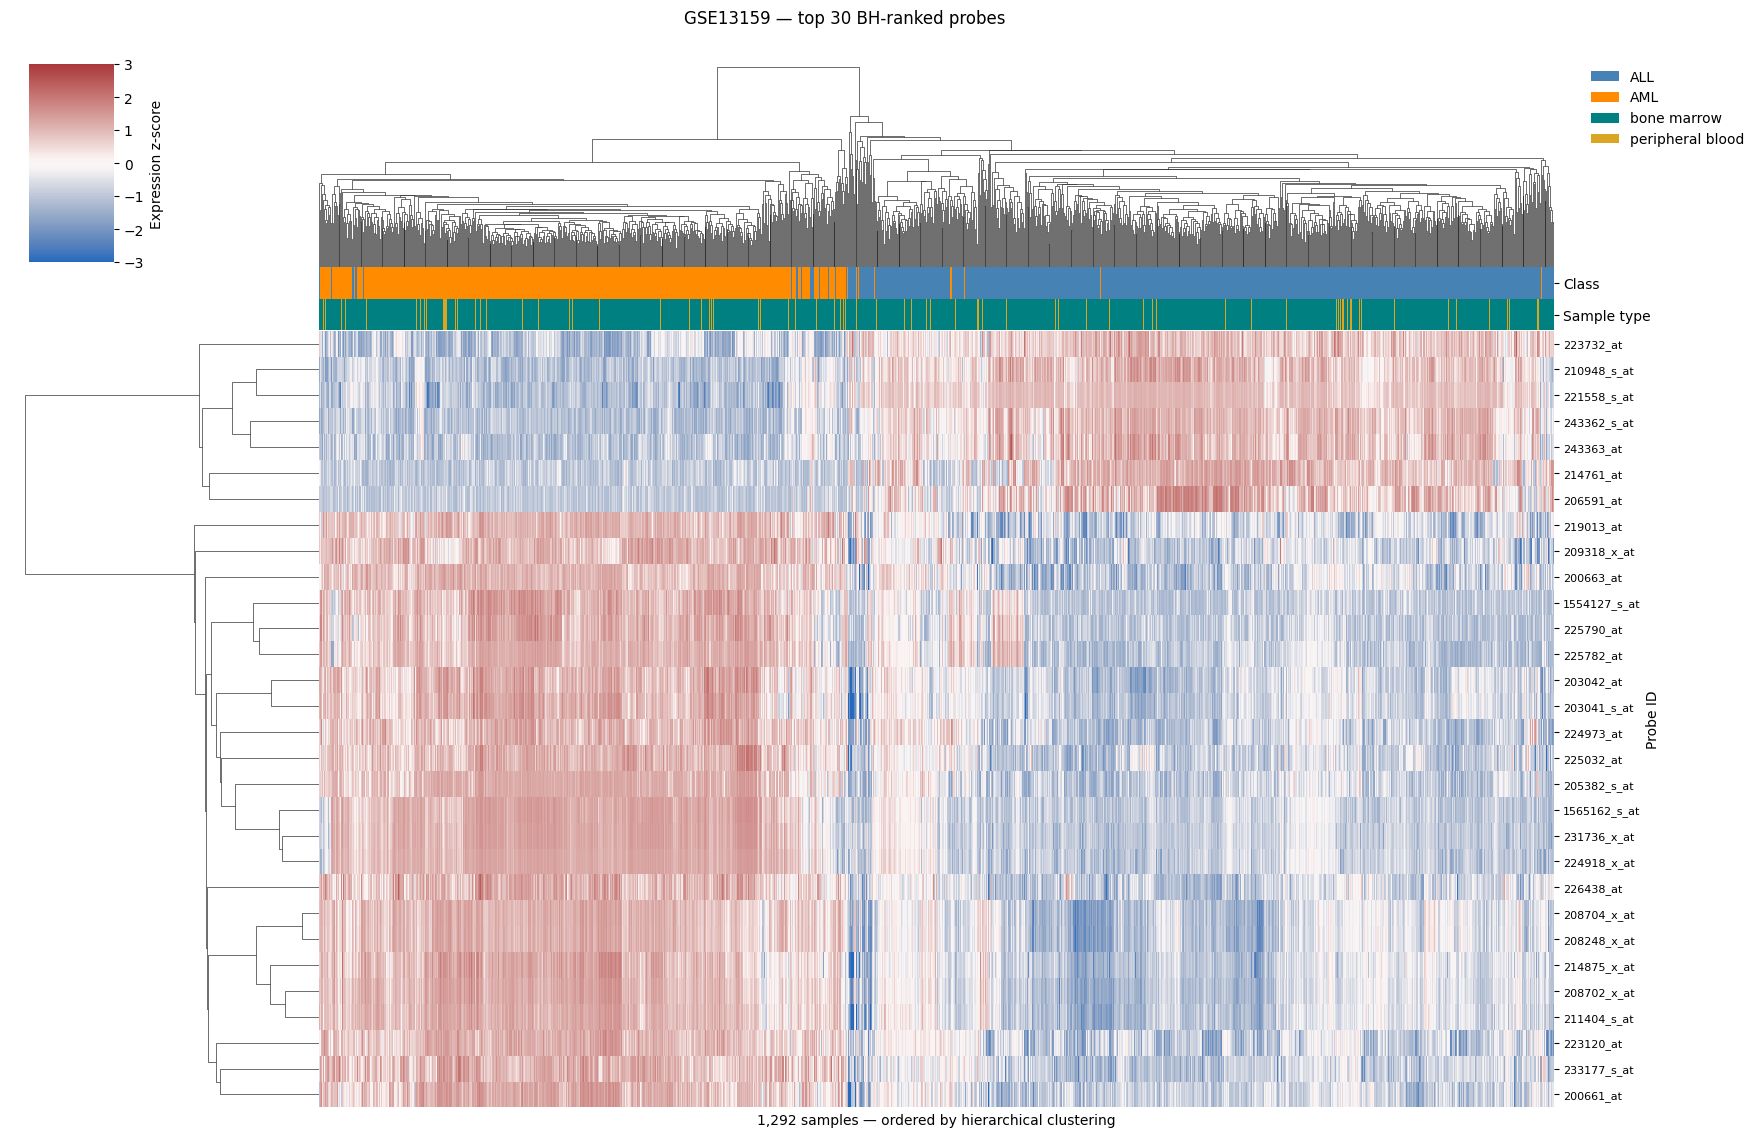

SVG kaydedildi: /content/all_aml_external_outputs/gse13159_top30_probe_heatmap.svg


In [ ]:
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Eşit p-değerlerinde tekrarlanabilir sıralama.
ranked_probes = (
    external_probe_stats
    .loc[external_probe_stats["significant_BH_0.05"]]
    .reset_index()
    .sort_values(["p_adj_BH", "p_value", "probe_id"])
)

top_external_probes = ranked_probes.head(30)["probe_id"].tolist()
assert len(top_external_probes) == 30

# Satırlar prob, sütunlar örnek.
heatmap_data = X_external_clean.loc[:, top_external_probes].T

# Her probu örnekler boyunca standartlaştır; yalnızca görselleştirme.
heatmap_z = heatmap_data.sub(
    heatmap_data.mean(axis=1), axis=0
).div(
    heatmap_data.std(axis=1, ddof=1), axis=0
)

assert np.isfinite(heatmap_z.to_numpy()).all()

plot_metadata = selected_metadata.loc[heatmap_z.columns]

class_palette = {"ALL": "steelblue", "AML": "darkorange"}
type_palette = {
    "bone marrow": "teal",
    "peripheral blood": "goldenrod"
}

column_colors = pd.DataFrame({
    "Class": plot_metadata["class"].map(class_palette),
    "Sample type": plot_metadata["sample_type"].map(type_palette)
})

g_external = sns.clustermap(
    heatmap_z,
    cmap="vlag",
    center=0,
    vmin=-3,
    vmax=3,
    method="average",
    metric="euclidean",
    col_colors=column_colors,
    figsize=(17, 11),
    xticklabels=False,
    yticklabels=True,
    cbar_kws={"label": "Expression z-score"}
)

g_external.ax_heatmap.set_xlabel(
    "1,292 samples — ordered by hierarchical clustering"
)
g_external.ax_heatmap.set_ylabel("Probe ID")
g_external.ax_heatmap.tick_params(axis="y", labelsize=8)

g_external.fig.suptitle(
    "GSE13159 — top 30 BH-ranked probes",
    y=1.03
)

legend_items = [
    Patch(facecolor=color, label=name)
    for palette in [class_palette, type_palette]
    for name, color in palette.items()
]

g_external.ax_col_dendrogram.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

# SVG içindeki yazıları metin olarak koru.
plt.rcParams["svg.fonttype"] = "none"

output_dir = Path("/content/all_aml_external_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

svg_path = output_dir / "gse13159_top30_probe_heatmap.svg"
g_external.savefig(svg_path, bbox_inches="tight")

plt.show()
print("SVG kaydedildi:", svg_path)